In [1]:
# These notebooks live in notebooks/d1_dev/ but use paths relative to the repo root
# (data/, protocol/, reports/, ...) and import from src/: go back to the root first.
# The test makes it harmless to run twice, or to run from the root.
import os
from pathlib import Path

if not Path("src").exists():
    os.chdir(Path.cwd().parents[1])

# 01 — MLP baseline

A fully connected network on raw 128x128 pixels, compared with a majority-class baseline and a decision tree on image metadata.
Two scopes are trained from scratch: Photo vs Text only, and the full dataset (Photo vs the 4 other origins).

In [2]:
import os
import time
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf
import keras
from sklearn.metrics import balanced_accuracy_score
from sklearn.tree import DecisionTreeClassifier
from src.utils import CACHE, METRICS, class_weights, evaluate, load_images

T0 = time.time()
gpus = tf.config.list_physical_devices("GPU")
if not gpus:
    raise SystemExit("No GPU found by TensorFlow: check the kernel and the CUDA libraries (see README) before running this notebook.")
tf.config.experimental.set_memory_growth(gpus[0], True)
print("GPU:", gpus)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| numpy", np.__version__,
      "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

REPORTS = Path("reports")
CACHE.mkdir(exist_ok=True)
REPORTS.mkdir(exist_ok=True)
SEED, SIZE, EPOCHS, BATCH = 42, 128, 15, 32

I0000 00:00:1791918364.598087  282657 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791918366.936060  282657 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
TensorFlow 2.21.0 | Keras 3.15.1 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1


In [2]:
manifest = pd.read_csv("protocol/manifest.csv")
df = manifest[manifest["drop_reason"].isna()].reset_index(drop=True)
counts = pd.crosstab(df["origin"], df["split"], margins=True, margins_name="total")
print(counts[["train", "val", "test", "total"]])
test = df[df["split"] == "test"]
photo_share = (test["label"] == 1).mean()
print(f"\nPhoto share in test: {photo_share:.4f} -> majority-class accuracy: {1 - photo_share:.4f}")

split       train   val  test  total
origin                              
Painting     6997  1499  1500   9996
Photo        6995  1499  1499   9993
Schematics   6236  1336  1336   8908
Sketch        984   211   211   1406
Text         6999  1500  1500   9999
total       28211  6045  6046  40302

Photo share in test: 0.2479 -> majority-class accuracy: 0.7521


## Helpers

Images are resized to 128x128 without keeping the aspect ratio and converted to RGB (grayscale, palette and CMYK files included).
Class weights are computed on the training rows only, so validation and test stay untouched.

In [3]:
t = time.time()
splits = {s: df[df["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"]}
X = {s: load_images(d, SIZE) for s, d in splits.items()}
y = {s: d["label"].to_numpy() for s, d in splits.items()}
for s in X:
    print(s, X[s].shape, X[s].dtype, f"{X[s].nbytes / 1e9:.2f} GB")
print(f"Loaded in {time.time() - t:.0f} s")

train (28211, 128, 128, 3) uint8 1.39 GB
val (6045, 128, 128, 3) uint8 0.30 GB
test (6046, 128, 128, 3) uint8 0.30 GB
Loaded in 2 s


## Baselines (full test set)

The majority class always predicts non-Photo, so its Photo precision, recall and F1 are 0 and its PR-AUC equals the Photo share.
The decision tree uses only width, height, aspect ratio and colour mode; its depth is chosen on validation balanced accuracy.

In [4]:
baselines = {"majority": evaluate(y["test"], np.zeros(len(y["test"])), splits["test"]["origin"])}

def meta_features(d):
    f = pd.DataFrame({"width": d["width"], "height": d["height"], "ratio": d["width"] / d["height"]})
    for m in sorted(df["mode"].unique()):
        f[f"mode_{m}"] = (d["mode"] == m).astype(int)
    return f

F = {s: meta_features(d) for s, d in splits.items()}
cw_full = class_weights(y["train"])
val_bacc = {}
for depth in range(1, 13):
    tree = DecisionTreeClassifier(max_depth=depth, class_weight=cw_full, random_state=42).fit(F["train"], y["train"])
    val_bacc[depth] = balanced_accuracy_score(y["val"], tree.predict(F["val"]))
best_depth = max(val_bacc, key=val_bacc.get)
print("Validation balanced accuracy by depth:", {k: round(v, 4) for k, v in val_bacc.items()})
print("Selected depth:", best_depth)
tree = DecisionTreeClassifier(max_depth=best_depth, class_weight=cw_full, random_state=42).fit(F["train"], y["train"])
baselines["decision_tree_meta"] = evaluate(y["test"], tree.predict_proba(F["test"])[:, 1], splits["test"]["origin"])
pd.DataFrame({k: {m: v[m] for m in METRICS} for k, v in baselines.items()}).T.round(4)

Validation balanced accuracy by depth: {1: 0.8165, 2: 0.8718, 3: 0.9216, 4: 0.9256, 5: 0.9256, 6: 0.9711, 7: 0.9817, 8: 0.983, 9: 0.982, 10: 0.9835, 11: 0.9835, 12: 0.9832}
Selected depth: 10


,precision,recall,f1,balanced_acc,pr_auc,accuracy
majority,0.0000,0.0000,0.0000,0.5000,0.2479,0.7521
decision_tree_meta,0.9641,0.9853,0.9746,0.9866,0.9849,0.9873


What I observe

Observed:
- The metadata tree reaches 0.99 balanced accuracy on test, far above the majority class.

Meaning: image format alone probably nearly separates Photo from the other origins, so the tree is the bar for any pixel model.

Dense(128) holds almost all weights: 49,152 × 128 + 128 = 6,291,584 of the 6,299,905 parameters.
Binary cross-entropy is used with class_weight so that both classes weigh the same in total; Adam uses its default learning rate of 1e-3.

In [5]:
def build_mlp(seed):
    keras.utils.set_random_seed(seed)
    model = keras.Sequential([
        keras.Input((SIZE, SIZE, 3)),
        keras.layers.Rescaling(1 / 255),
        keras.layers.Flatten(),
        keras.layers.Dense(128, activation="relu"),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
    return model

build_mlp(42).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 49152)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,291,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,299,905 (24.03 MB)

 Trainable params: 6,299,905 (24.03 MB)

 Non-trainable params: 0 (0.00 B)

## Training: two scopes, seed 42

Validation is passed as (x_val, y_val, sample_weight_val) with the same class weights as training, so train and validation losses are comparable; the accuracy metric is not weighted.
Each scope is trained from scratch for 15 epochs and the last-epoch weights are kept; test predictions are stored here but only reported in the Results section.

In [6]:
SCOPES = {"photo_vs_text": ["Photo", "Text"], "full": sorted(df["origin"].unique())}
mask = {(sc, s): splits[s]["origin"].isin(o).to_numpy() for sc, o in SCOPES.items() for s in splits}

def run_scope(scope, seed=SEED):
    tr, va, te = mask[(scope, "train")], mask[(scope, "val")], mask[(scope, "test")]
    cw = class_weights(y["train"][tr])
    sw_val = np.where(y["val"][va] == 1, cw[1], cw[0])
    model = build_mlp(seed)
    t = time.time()
    hist = model.fit(X["train"][tr], y["train"][tr], validation_data=(X["val"][va], y["val"][va], sw_val),
                     epochs=EPOCHS, batch_size=BATCH, class_weight=cw, verbose=0)
    out = {"history": hist.history, "time_s": time.time() - t,
           "val": evaluate(y["val"][va], model.predict(X["val"][va], verbose=0), splits["val"]["origin"][va]),
           "proba_test": model.predict(X["test"], verbose=0).ravel()}  # full test set, subset later
    keras.backend.clear_session()
    return out

runs = {}
for scope in SCOPES:
    runs[scope] = r = run_scope(scope)
    print(f"{scope:14s}: {r['time_s']:.0f} s | val balanced acc {r['val']['balanced_acc']:.4f}")

photo_vs_text : 38 s | val balanced acc 0.9937


full          : 56 s | val balanced acc 0.8172


In [7]:
pd.DataFrame({sc: {m: runs[sc]["val"][m] for m in METRICS} for sc in SCOPES}).T.round(4)

,precision,recall,f1,balanced_acc,pr_auc,accuracy
photo_vs_text,0.9973,0.9900,0.9936,0.9937,0.9995,0.9937
full,0.5204,0.9113,0.6625,0.8172,0.6081,0.7697


What I observe

Observed:
- Validation balanced accuracy is 0.99 for Photo vs Text and 0.82 for the full scope.

Meaning: separating Photo from four origins is probably much harder for the MLP than separating it from Text alone.

## Learning curves

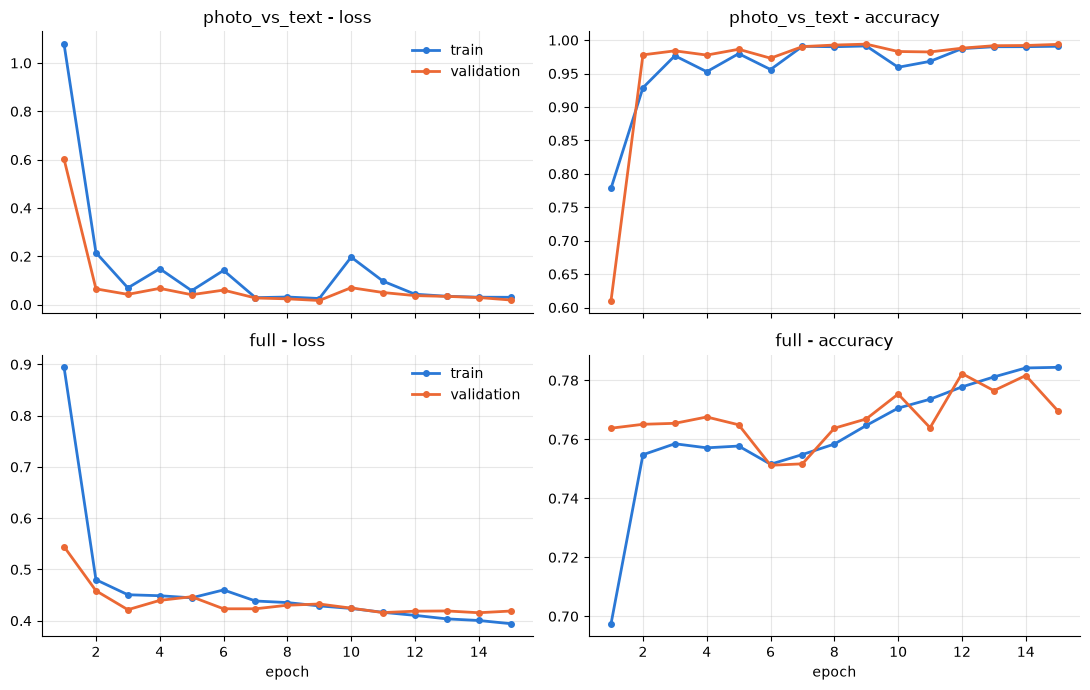

Last epoch (15) unless stated otherwise


,loss,val_loss,accuracy,val_accuracy,min val_accuracy,max val_accuracy,epoch of max val_accuracy
photo_vs_text,0.0306,0.0193,0.9909,0.9937,0.6105,0.9940,9.0
full,0.3943,0.4189,0.7844,0.7697,0.7512,0.7823,12.0


In [8]:
C_TRAIN, C_VAL = "#2a78d6", "#eb6834"
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
epochs = np.arange(1, EPOCHS + 1)
for i, scope in enumerate(SCOPES):
    h = runs[scope]["history"]
    for j, m in enumerate(["loss", "accuracy"]):
        ax = axes[i, j]
        ax.plot(epochs, h[m], color=C_TRAIN, lw=2, marker="o", ms=4, label="train")
        ax.plot(epochs, h[f"val_{m}"], color=C_VAL, lw=2, marker="o", ms=4, label="validation")
        ax.set_title(f"{scope} - {m}")
        ax.grid(alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)
    axes[i, 0].legend(frameon=False)
for ax in axes[1]:
    ax.set_xlabel("epoch")
plt.tight_layout()
plt.savefig(REPORTS / "01_mlp_curves.png", dpi=120)
plt.show()

rows = {}
for sc, r in runs.items():
    h = r["history"]
    rows[sc] = {"loss": h["loss"][-1], "val_loss": h["val_loss"][-1],
                "accuracy": h["accuracy"][-1], "val_accuracy": h["val_accuracy"][-1],
                "min val_accuracy": min(h["val_accuracy"]), "max val_accuracy": max(h["val_accuracy"]),
                "epoch of max val_accuracy": int(np.argmax(h["val_accuracy"])) + 1}
print(f"Last epoch ({EPOCHS}) unless stated otherwise")
pd.DataFrame(rows).T.round(4)

What I observe

Observed:
- Full-scope validation accuracy moves between 0.75 and 0.78 across epochs.
- It shows no clear upward trend after the first epochs.

Meaning: more epochs would probably add little for the full-scope MLP.

## Results on the test set

Test metrics are computed once here, at threshold 0.5, on the natural test distribution of each scope.

In [9]:
test_eval = {sc: evaluate(y["test"][mask[(sc, "test")]], r["proba_test"][mask[(sc, "test")]],
                          splits["test"]["origin"][mask[(sc, "test")]]) for sc, r in runs.items()}
pt = mask[("photo_vs_text", "test")]
pt_full_model = evaluate(y["test"][pt], runs["full"]["proba_test"][pt], splits["test"]["origin"][pt])

table_full = pd.DataFrame({k: {m: f"{v[m]:.4f}" for m in METRICS} for k, v in baselines.items()}).T
table_full.loc["mlp (seed 42)"] = {m: f"{test_eval['full'][m]:.4f}" for m in METRICS}
table_full.drop("majority").rename_axis("model").to_csv(REPORTS / "test_results.csv")  # shared with later notebooks
print("Full scope, test set (n = %d)" % len(y["test"]))
display(table_full)

table_pt = pd.DataFrame({"mlp trained on photo_vs_text": {m: test_eval["photo_vs_text"][m] for m in METRICS},
                         "mlp trained on full scope": {m: pt_full_model[m] for m in METRICS}}).T.round(4)
print("Photo + Text test rows only (n = %d)" % pt.sum())
display(table_pt)

Full scope, test set (n = 6046)


,precision,recall,f1,balanced_acc,pr_auc,accuracy
majority,0.0000,0.0000,0.0000,0.5000,0.2479,0.7521
decision_tree_meta,0.9641,0.9853,0.9746,0.9866,0.9849,0.9873
mlp (seed 42),0.5099,0.9093,0.6534,0.8106,0.6152,0.7608


Photo + Text test rows only (n = 2999)


,precision,recall,f1,balanced_acc,pr_auc,accuracy
mlp trained on photo_vs_text,0.9993,0.9873,0.9933,0.9933,0.9999,0.9933
mlp trained on full scope,1.0000,0.9093,0.9525,0.9546,0.9999,0.9547


In [10]:
cols = ["balanced_acc", "f1", "accuracy"]
for name, b in baselines.items():
    d = 100 * (pd.Series({m: test_eval["full"][m] for m in cols}) - pd.Series({m: b[m] for m in cols}))
    print(f"MLP - {name} (points):", d.round(2).to_dict())

MLP - majority (points): {'balanced_acc': 31.06, 'f1': 65.34, 'accuracy': 0.88}
MLP - decision_tree_meta (points): {'balanced_acc': -17.6, 'f1': -32.12, 'accuracy': -22.64}


MLP full scope: [[TN FP] [FN TP]] = [[3237, 1310], [136, 1363]]
decision_tree_meta: [[TN FP] [FN TP]] = [[4492, 55], [22, 1477]]


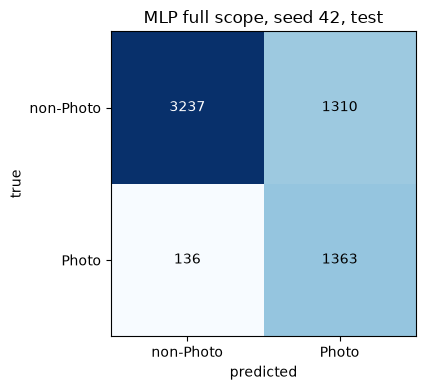

In [11]:
print("MLP full scope: [[TN FP] [FN TP]] =", test_eval["full"]["cm"].tolist())
print("decision_tree_meta: [[TN FP] [FN TP]] =", baselines["decision_tree_meta"]["cm"].tolist())

cm = test_eval["full"]["cm"]
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, v, ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["non-Photo", "Photo"])
ax.set_yticks([0, 1], ["non-Photo", "Photo"])
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title("MLP full scope, seed 42, test")
plt.tight_layout()
plt.savefig(REPORTS / "01_mlp_confusion.png", dpi=120)
plt.show()

            majority  decision_tree_meta     mlp
Painting         0.0              0.0320  0.7060
Photo            1.0              0.0147  0.0907
Schematics       0.0              0.0052  0.1879
Sketch           0.0              0.0000  0.0000
Text             0.0              0.0000  0.0000


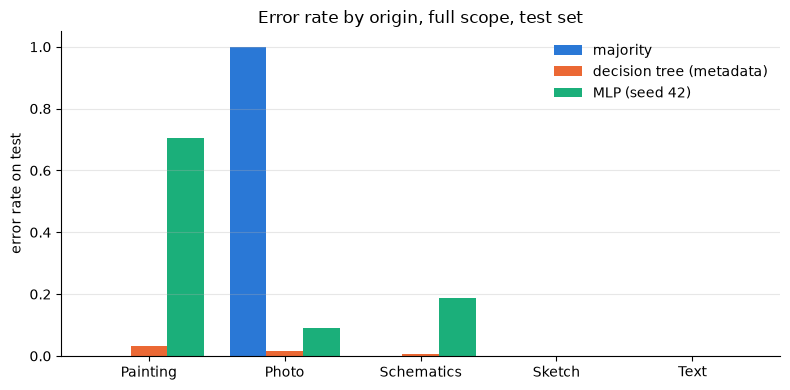

Total notebook runtime: 1.8 min


In [12]:
err = pd.DataFrame({"majority": baselines["majority"]["error_by_origin"],
                    "decision_tree_meta": baselines["decision_tree_meta"]["error_by_origin"],
                    "mlp": test_eval["full"]["error_by_origin"]})
print(err.round(4))

origins, w = list(err.index), 0.27
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(origins))
ax.bar(x - w, err["majority"], w, color="#2a78d6", label="majority")
ax.bar(x, err["decision_tree_meta"], w, color="#eb6834", label="decision tree (metadata)")
ax.bar(x + w, err["mlp"], w, color="#1baf7a", label="MLP (seed 42)")
ax.set_xticks(x, origins)
ax.set_ylabel("error rate on test")
ax.set_title("Error rate by origin, full scope, test set")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(REPORTS / "01_mlp_error_by_origin.png", dpi=120)
plt.show()
print(f"Total notebook runtime: {(time.time() - T0) / 60:.1f} min")

What I observe

Observed:
- On test, false positives far outnumber false negatives for the MLP.
- Painting has the highest MLP error rate (0.71).

Meaning: the low Photo precision probably comes from false alarms on Painting, not from missed photos.

## Analysis

(a) Train vs validation gap

Observed:
- Full scope, last epoch: train accuracy 0.78, validation accuracy 0.77.
- Photo vs Text: validation accuracy is at or above train accuracy.

Meaning: there is probably no overfitting; the full-scope MLP may be underfitting (to check: larger or longer-trained model).

(b) MLP vs baselines

Observed:
- MLP test balanced accuracy is 0.81, well above the majority class.
- It is about 18 points below the metadata tree.

Meaning: the MLP probably learns more than the class prior but far less than image format alone provides.

(c) Origin with the highest error rate

Observed:
- Painting is the hardest origin for both the MLP (0.71) and the tree (0.03).
- Schematics is the next hardest for the MLP.

Meaning: Painting is probably the main source of the MLP's false positives, since a non-Photo error is a false positive.

(d) Photo vs Text scope vs full scope

Observed:
- On the same Photo + Text test rows, balanced accuracy is 0.99 for the Photo vs Text MLP and 0.95 for the full-scope MLP.
- Photo precision is near 1.00 for both, so the gap is in Photo recall.

Meaning: the gap probably comes from the full-scope model missing photos.